In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split

In [2]:
# --------------------------------------------------
# STEP 1: LOAD AND PREPROCESS DATA
# --------------------------------------------------

data = pd.read_csv("IMDB Dataset.csv")

# Convert sentiment into numerical values
data['sentiment'] = data['sentiment'].map({
    'positive': 1,
    'negative': 0
})

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    data['review'].astype(str),
    data['sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=data['sentiment']
)

# Convert reviews into words
def preprocess_text(text):

    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    words = text.split()

    # Remove stop words
    words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    return words


train_sentences = [
    preprocess_text(review)
    for review in X_train
]

test_sentences = [
    preprocess_text(review)
    for review in X_test
]

print("Training documents:", len(train_sentences))
print("Testing documents:", len(test_sentences))


Training documents: 40000
Testing documents: 10000


In [3]:
# --------------------------------------------------
# STEP 2: TRAIN CBOW WORD2VEC MODEL
# --------------------------------------------------

model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=0,
    epochs=10
)

print("CBOW Word2Vec Model Trained Successfully")

CBOW Word2Vec Model Trained Successfully


In [4]:
# --------------------------------------------------
# STEP 3: CONVERT DOCUMENTS INTO EMBEDDINGS
# --------------------------------------------------

def document_vector(words):

    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)


X_train_vectors = np.array([
    document_vector(doc)
    for doc in train_sentences
])

X_test_vectors = np.array([
    document_vector(doc)
    for doc in test_sentences
])

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Training vector shape:", X_train_vectors.shape)
print("Testing vector shape:", X_test_vectors.shape)

Training vector shape: (40000, 100)
Testing vector shape: (10000, 100)


In [5]:
# --------------------------------------------------
# STEP 4: BUILD FEED FORWARD NEURAL NETWORK
# --------------------------------------------------

classifier = keras.Sequential([
    layers.Input(shape=(100,)),

    layers.Dense(64, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

classifier.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

classifier.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# --------------------------------------------------
# STEP 5: TRAIN THE CLASSIFICATION MODEL
# --------------------------------------------------

history = classifier.fit(
    X_train_vectors,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


Epoch 1/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.8276 - loss: 0.3868 - val_accuracy: 0.8558 - val_loss: 0.3268
Epoch 2/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8575 - loss: 0.3387 - val_accuracy: 0.8622 - val_loss: 0.3177
Epoch 3/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8605 - loss: 0.3287 - val_accuracy: 0.8597 - val_loss: 0.3153
Epoch 4/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8626 - loss: 0.3245 - val_accuracy: 0.8620 - val_loss: 0.3134
Epoch 5/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8657 - loss: 0.3216 - val_accuracy: 0.8625 - val_loss: 0.3112
Epoch 6/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8662 - loss: 0.3178 - val_accuracy: 0.8625 - val_loss: 0.3115
Epoch 7/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8689 - loss: 0.3153 - val_accuracy: 0.8648 - val_loss: 0.3096
Epoch 8/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8683 - loss: 0.3130 - val_accuracy: 0

In [7]:
# --------------------------------------------------
# STEP 6: EVALUATE THE MODEL
# --------------------------------------------------

loss, accuracy = classifier.evaluate(
    X_test_vectors,
    y_test
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8707 - loss: 0.3100
Test Loss: 0.3100045621395111
Test Accuracy: 0.8707000017166138


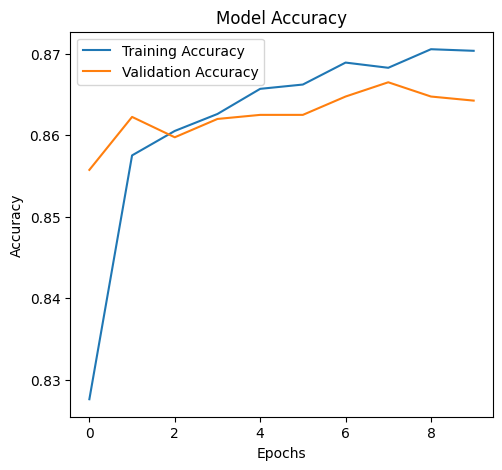

In [8]:
# --------------------------------------------------
# STEP 7: PLOT ACCURACY AND LOSS
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


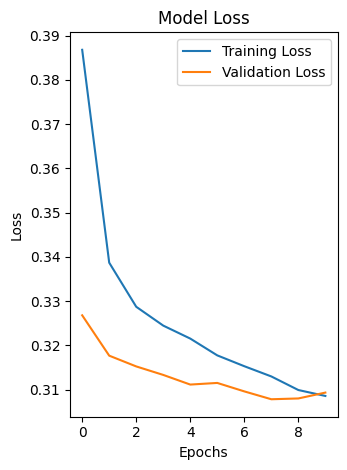

In [9]:
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [16]:
# --------------------------------------------------
# STEP 8: FIND SIMILAR WORDS USING CBOW
# --------------------------------------------------

print("\nSimilar words:")

print(
    model.wv.most_similar(
        'movie',
        topn=5
    )
)

# Save CBOW model
model.save("cbow_model.model")

print("CBOW Model Saved Successfully")



Similar words:
[('film', 0.8282096982002258), ('movies', 0.7136207222938538), ('flick', 0.6462371945381165), ('really', 0.598932147026062), ('just', 0.5507677793502808)]
CBOW Model Saved Successfully
